In [ ]:
import re
import nltk
import string
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pt
from sklearn.metrics import f1_score

pd.set_option("display.max_colwidth",200)



In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd

# Paste the path you copied from the file browser
test = '/content/drive/MyDrive/Colab Notebooks/Supervised Learning/Sentiment Analysis/test_tweets_anuFYb8.csv'
train = '/content/drive/MyDrive/Colab Notebooks/Supervised Learning/Sentiment Analysis/train_E6oV3lV.csv'

test = pd.read_csv(test)
train = pd.read_csv(train)

train.head()



,id,label,tweet
0,1,0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0,factsguide: society now #motivation


In [ ]:
import os
# os.listdir('/content/drive/MyDrive/Colab Notebooks/Sentiment Analysis/')

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      31962 non-null  int64 
 1   label   31962 non-null  int64 
 2   tweet   31962 non-null  object
dtypes: int64(2), object(1)
memory usage: 749.2+ KB


In [ ]:
train.describe()



,id,label
count,31962.000000,31962.000000
mean,15981.500000,0.070146
std,9226.778988,0.255397
min,1.000000,0.000000
25%,7991.250000,0.000000
50%,15981.500000,0.000000
75%,23971.750000,0.000000
max,31962.000000,1.000000


In [ ]:
train.describe(include='object')

,tweet
count,31962
unique,29530
top,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
freq,319


In [ ]:
train[train['label']==0].head(10)

,id,label,tweet
0,1,0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0,factsguide: society now #motivation
5,6,0,[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo
6,7,0,@user camping tomorrow @user @user @user @user @user @user @user dannyâ¦
7,8,0,the next school year is the year for exams.ð¯ can't think about that ð­ #school #exams #hate #imagine #actorslife #revolutionschool #girl
8,9,0,we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers â¦
9,10,0,@user @user welcome here ! i'm it's so #gr8 !


In [ ]:
train.shape

(31962, 3)

In [ ]:
train['label'].value_counts()

,count
label,
0,29720
1,2242


In [ ]:
comb = pd.concat([train,test],ignore_index=True)

comb.tail(20)



,id,label,tweet
49139,49140,NaN,i am thankful for children. #thankful #positive
49140,49141,NaN,liverpool â¤ï¸ð¬ð§ #walk #liverpool #starbucks #avidaeboa #passeio #chocolate #deliciousâ¦
49141,49142,NaN,#bakersfield rooster simulation: i want to climb the vast expanse of mountains. it reached the leakage coc
49142,49143,NaN,por do sol ó¾â¤ï¸#instagood #beautiful #instadaily #instalike #instamood #amazing #bestoftheday #cool...
49143,49144,NaN,@user hell yeah what a great surprise for your present enjoy this picture of me #bihday
49144,49145,NaN,when ur the joke ur defensive towards everythingð¯
49145,49146,NaN,#enjoying the #evening #sun in my #bedroom â¨ #cozy evening ð #homesweethome #allwhiteâ¦
49146,49147,NaN,tonight on @user from 9pm gmt you can here a special early play of a new song from the upcoming album! !
49147,49148,NaN,today is a good day for excercise #imready #sofuckenready #letsgo #comeon #letsgetsta
49148,49149,NaN,good night with a tea and music âï¸ððð» #billy #music #tea #mug #tokiohotelmug #tokiohotel â¦


In [ ]:
comb['tweet'] = comb['tweet'].str.replace("@\w+","",regex=True)
comb.head()

<>:1: SyntaxWarning: invalid escape sequence '\w'
<>:1: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipykernel_450/4178194974.py:1: SyntaxWarning: invalid escape sequence '\w'
  comb['tweet'] = comb['tweet'].str.replace("@\w+","",regex=True)


,id,label,tweet
0,1,0.0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0.0,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0.0,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0.0,factsguide: society now #motivation


In [ ]:
comb['new_tweet'] = comb['tweet']

comb.head()

,id,label,tweet,new_tweet
0,1,0.0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0.0,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked
2,3,0.0,bihday your majesty,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0.0,factsguide: society now #motivation,factsguide: society now #motivation


In [ ]:
comb['new_tweet'] = comb['new_tweet'].str.replace(r"[^a-zA-Z#]"," ",regex=True)

comb.head()

,id,label,tweet,new_tweet
0,1,0.0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction #run
1,2,0.0,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks for #lyft credit i can t use cause they don t offer wheelchair vans in pdx #disapointed #getthanked
2,3,0.0,bihday your majesty,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,#model i love u take with u all the time in ur
4,5,0.0,factsguide: society now #motivation,factsguide society now #motivation


In [ ]:
comb['new_tweet'] = comb['new_tweet'].apply(lambda x: ' '.join([ w for w in x.split() if len(w) > 3]))

comb.head()

,id,label,tweet,new_tweet
0,1,0.0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when father dysfunctional selfish drags kids into dysfunction #run
1,2,0.0,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks #lyft credit cause they offer wheelchair vans #disapointed #getthanked
2,3,0.0,bihday your majesty,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,#model love take with time
4,5,0.0,factsguide: society now #motivation,factsguide society #motivation


In [ ]:
comb['new_tweet'] = comb['new_tweet'].str.replace("[^a-zA-Z#]"," ",regex=True)

comb.head()

,id,label,tweet,new_tweet
0,1,0.0,when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run,when father dysfunctional selfish drags kids into dysfunction #run
1,2,0.0,thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #getthanked,thanks #lyft credit cause they offer wheelchair vans #disapointed #getthanked
2,3,0.0,bihday your majesty,bihday your majesty
3,4,0.0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦,#model love take with time
4,5,0.0,factsguide: society now #motivation,factsguide society #motivation


In [ ]:
import nltk
nltk.download('wordnet')

from nltk.stem import WordNetLemmatizer

# ps = PorterStemmer()

lm = WordNetLemmatizer()

lm.lemmatize("singing")

[nltk_data] Downloading package wordnet to /root/nltk_data...


'singing'

In [ ]:
nltk.download('wordnet')
nltk.download('omw-1.4')
# print(nltk.data.path)

from nltk.corpus import wordnet as wn

wn.synsets("running")




[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


[Synset('run.n.05'),
 Synset('run.n.07'),
 Synset('running.n.03'),
 Synset('running.n.04'),
 Synset('track.n.11'),
 Synset('run.v.01'),
 Synset('scat.v.01'),
 Synset('run.v.03'),
 Synset('operate.v.01'),
 Synset('run.v.05'),
 Synset('run.v.06'),
 Synset('function.v.01'),
 Synset('range.v.01'),
 Synset('campaign.v.01'),
 Synset('play.v.18'),
 Synset('run.v.11'),
 Synset('tend.v.01'),
 Synset('run.v.13'),
 Synset('run.v.14'),
 Synset('run.v.15'),
 Synset('run.v.16'),
 Synset('prevail.v.03'),
 Synset('run.v.18'),
 Synset('run.v.19'),
 Synset('carry.v.15'),
 Synset('run.v.21'),
 Synset('guide.v.05'),
 Synset('run.v.23'),
 Synset('run.v.24'),
 Synset('run.v.25'),
 Synset('run.v.26'),
 Synset('run.v.27'),
 Synset('run.v.28'),
 Synset('run.v.29'),
 Synset('run.v.30'),
 Synset('run.v.31'),
 Synset('run.v.32'),
 Synset('run.v.33'),
 Synset('run.v.34'),
 Synset('ply.v.03'),
 Synset('hunt.v.01'),
 Synset('race.v.02'),
 Synset('move.v.13'),
 Synset('melt.v.01'),
 Synset('ladder.v.01'),
 Synset('ru

In [ ]:

res = wn.synsets("runn")[0]
res.name()

# res.definition()

# res.examples()

# lemm = res.lemmas()[1]

# lemm.name()

# lemm = res.lemma_names()

# t1 = res.hypernyms()[0]

# t1.definition()

# lemm = res.lemmas()[0].antonyms()

# lemm

# res


IndexError: list index out of range

In [ ]:
tokenize_tweet = comb['new_tweet'].apply(lambda x: x.split())

tokenize_tweet.head()

,new_tweet
0,"[when, father, dysfunctional, selfish, drags, kids, into, dysfunction, #run]"
1,"[thanks, #lyft, credit, cause, they, offer, wheelchair, vans, #disapointed, #getthanked]"
2,"[bihday, your, majesty]"
3,"[#model, love, take, with, time]"
4,"[factsguide, society, #motivation]"


In [ ]:
tokenize_tweet = comb['new_tweet'].str.split(" ")

tokenize_tweet.head()

,new_tweet
0,"[when, father, dysfunctional, selfish, drags, kids, into, dysfunction, #run]"
1,"[thanks, #lyft, credit, cause, they, offer, wheelchair, vans, #disapointed, #getthanked]"
2,"[bihday, your, majesty]"
3,"[#model, love, take, with, time]"
4,"[factsguide, society, #motivation]"


In [ ]:
from nltk import PorterStemmer

ps = PorterStemmer()

tokenize_tweet = tokenize_tweet.apply(lambda x: ([ps.stem(w) for w in x]))

tokenize_tweet.head()

,new_tweet
0,"[when, father, dysfunct, selfish, drag, kid, into, dysfunct, #run]"
1,"[thank, #lyft, credit, caus, they, offer, wheelchair, van, #disapoint, #getthank]"
2,"[bihday, your, majesti]"
3,"[#model, love, take, with, time]"
4,"[factsguid, societi, #motiv]"


In [ ]:

for i in range(len(tokenize_tweet)):
  tokenize_tweet[i] = " ".join(tokenize_tweet[i])

tokenize_tweet.head()

,new_tweet
0,when father dysfunct selfish drag kid into dysfunct #run
1,thank #lyft credit caus they offer wheelchair van #disapoint #getthank
2,bihday your majesti
3,#model love take with time
4,factsguid societi #motiv


In [ ]:
comb['new_tweet'] = tokenize_tweet


In [ ]:
all_words = ' '.join(w for w in comb['new_tweet'])

all_words

'when father dysfunct selfish drag kid into dysfunct #run thank #lyft credit caus they offer wheelchair van #disapoint #getthank bihday your majesti #model love take with time factsguid societi #motiv huge fare talk befor they leav chao disput when they there #allshowandnogo camp tomorrow danni next school year year exam think about that #school #exam #hate #imagin #actorslif #revolutionschool #girl love land #allin #cav #champion #cleveland #clevelandcavali welcom here #ireland consum price index climb from previou #blog #silver #gold #forex selfish #orlando #standwithorlando #pulseshoot #orlandoshoot #biggerproblem #selfish #heabreak #valu #love daddi today day #gettingf #cnn call #michigan middl school build wall chant #tcot comment #australia #opkillingbay #seashepherd #helpcovedolphin #thecov #helpcovedolphin ouch junior angri #got #junior #yugyoem #omg thank have paner #thank #posit retweet agre #friday smile around user #cooki make peopl know essenti oil made chemic #euro peopl 

when father dysfunct selfish drag kid into dysfunct #run thank #lyft credit caus they offer wheelchair van #disapoint #getthank bihday your majesti #model love take with time factsguid societi #motiv huge fare talk befor they leav chao disput when they there #allshowandnogo camp tomorrow danni next school year year exam think about that #school #exam #hate #imagin #actorslif #revolutionschool #girl love land #allin #cav #champion #cleveland #clevelandcavali welcom here #ireland consum price index climb from previou #blog #silver #gold #forex selfish #orlando #standwithorlando #pulseshoot #orlandoshoot #biggerproblem #selfish #heabreak #valu #love daddi today day #gettingf #cnn call #michigan middl school build wall chant #tcot comment #australia #opkillingbay #seashepherd #helpcovedolphin #thecov #helpcovedolphin ouch junior angri #got #junior #yugyoem #omg thank have paner #thank #posit retweet agre #friday smile around user #cooki make peopl know essenti oil made chemic #euro peopl b

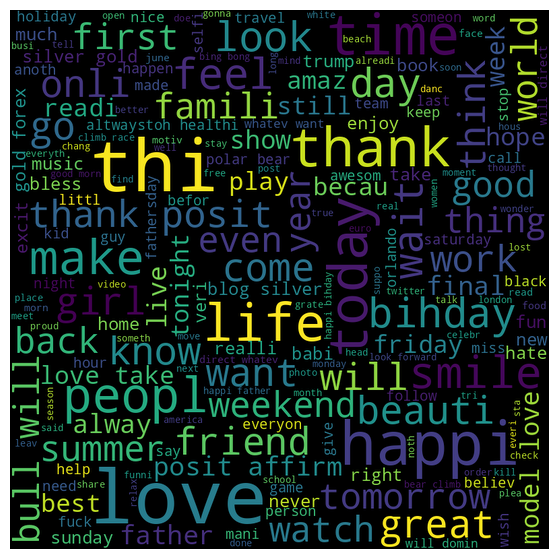

In [ ]:
from wordcloud import WordCloud

all_words = ' '.join(w for w in comb['new_tweet'])

print(all_words)

wc = WordCloud(width=800, height= 800, random_state=21, max_font_size=110).generate(all_words)

pt.figure(figsize=(10,7))
pt.axis('off')
pt.imshow(wc,interpolation="lanczos")

# pt.show()

(np.float64(-0.5), np.float64(799.5), np.float64(499.5), np.float64(-0.5))

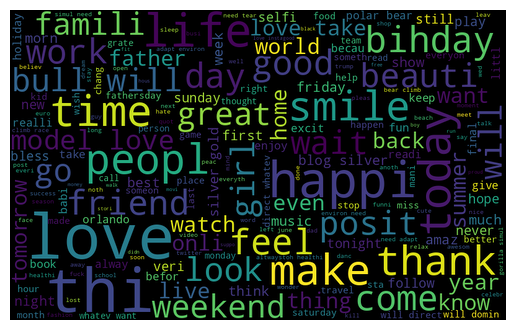

In [ ]:


normal_words = ''.join([w for w in  comb['new_tweet'][comb['label'] == 0]])

normal_words
wc = WordCloud(width=800,height=500,random_state=21,max_font_size=100).generate(normal_words)
pt.imshow(wc,interpolation="lanczos")
pt.axis('off')

(np.float64(-0.5), np.float64(799.5), np.float64(499.5), np.float64(-0.5))

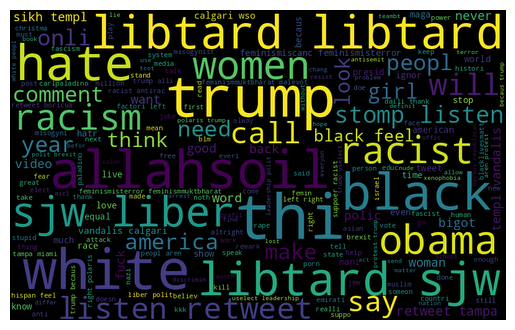

In [ ]:
negative_words = ''.join([w for w in comb['new_tweet'][comb['label'] == 1]])

wc = WordCloud(width=800,height=500,random_state=21,max_font_size=100).generate(negative_words)
pt.imshow(wc,interpolation="lanczos")
pt.axis('off')

In [ ]:
def extract_hastag(s):
  hashtag_bin = []
  for i in range(len(s)):
    hashtag_bin.append(re.findall(r'#[/w]+',i))
  return hashtag_bin

In [ ]:
# HT_normal = extract_hashtage(comb['new_tweet'][comb['label'] == 0])
# HT_normal = extract_hashtag(comb.loc[comb['label'] == 0,'tweet'])

# HT_normal


In [ ]:


HT_normal = comb.loc[comb['label'] == 1, "new_tweet"].str.findall('#[\w]+')
HT_negative = comb.loc[comb['label'] == 1,"new_tweet"].str.findall('#[\w]+')

HT_negative


<>:1: SyntaxWarning: invalid escape sequence '\w'
<>:2: SyntaxWarning: invalid escape sequence '\w'
<>:1: SyntaxWarning: invalid escape sequence '\w'
<>:2: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipykernel_450/2692906281.py:1: SyntaxWarning: invalid escape sequence '\w'
  HT_normal = comb.loc[comb['label'] == 1, "new_tweet"].str.findall('#[\w]+')
/tmp/ipykernel_450/2692906281.py:2: SyntaxWarning: invalid escape sequence '\w'
  HT_negative = comb.loc[comb['label'] == 1,"new_tweet"].str.findall('#[\w]+')


,new_tweet
13,"[#cnn, #michigan, #tcot]"
14,"[#australia, #opkillingbay, #seashepherd, #helpcovedolphin, #thecov, #helpcovedolphin]"
17,[]
23,[]
34,"[#neverump, #xenophobia]"
...,...
31934,"[#jcpenni, #kentucki]"
31946,"[#mailboxprid, #liberalism]"
31947,[]
31948,[]


In [ ]:
ht_normal = sum(HT_normal,[])
ht_neg = sum(HT_negative,[])

ht_normal

['#cnn',
 '#michigan',
 '#tcot',
 '#australia',
 '#opkillingbay',
 '#seashepherd',
 '#helpcovedolphin',
 '#thecov',
 '#helpcovedolphin',
 '#neverump',
 '#xenophobia',
 '#love',
 '#peac',
 '#race',
 '#ident',
 '#med',
 '#altright',
 '#whitesupremaci',
 '#linguist',
 '#race',
 '#power',
 '#raciolinguist',
 '#brexit',
 '#peopl',
 '#trump',
 '#republican',
 '#michelleobama',
 '#knick',
 '#golf',
 '#jewishsupremacist',
 '#libtard',
 '#sjw',
 '#liber',
 '#polit',
 '#trash',
 '#hate',
 '#stereotyp',
 '#prejudic',
 '#hope',
 '#hate',
 '#conflict',
 '#pol',
 '#bluelivesmatt',
 '#draintheswamp',
 '#ferguson',
 '#antisemit',
 '#hocoschool',
 '#columbiamd',
 '#hocomd',
 '#nazi',
 '#hatr',
 '#bigotri',
 '#libtard',
 '#sjw',
 '#liber',
 '#polit',
 '#fyi',
 '#tcot',
 '#topoli',
 '#blacklivesmatt',
 '#ushistori',
 '#eugen',
 '#biher',
 '#bigotri',
 '#altright',
 '#potu',
 '#theresist',
 '#crime',
 '#offic',
 '#black',
 '#retweet',
 '#tampa',
 '#miami',
 '#allahsoil',
 '#prais',
 '#cleveland',
 '#rnc',

/tmp/ipykernel_450/2016575857.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=freq_ls, x = 'Hashtag', y = 'Count', palette='viridis')


<Axes: xlabel='Hashtag', ylabel='Count'>

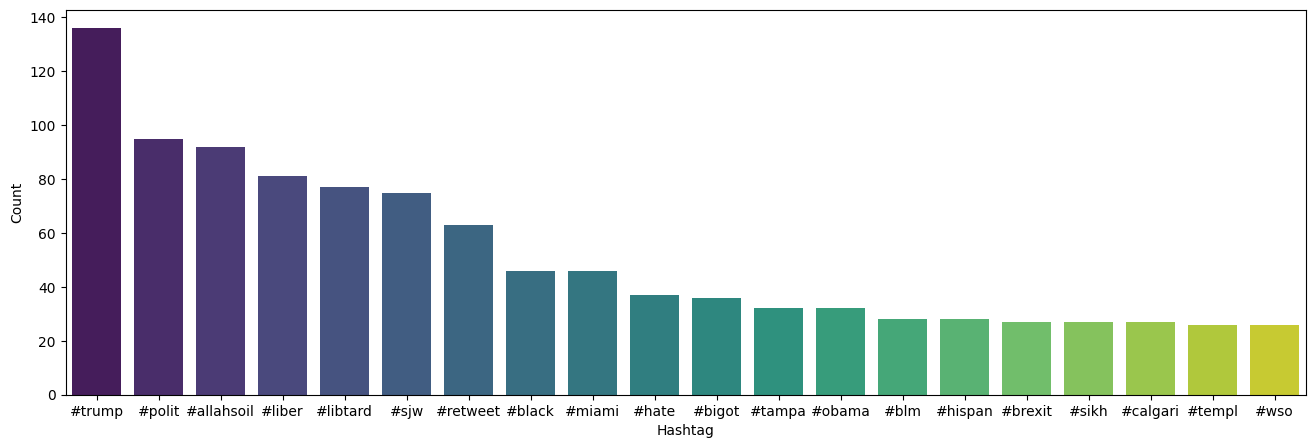

In [ ]:
import seaborn as sns

a = nltk.FreqDist(ht_normal)

freq_ls = pd.DataFrame({'Hashtag':list(a.keys()),'Count':list(a.values())})

freq_ls = freq_ls.nlargest(columns='Count',n=20)

pt.figure(figsize=(16,5))
sns.barplot(data=freq_ls, x = 'Hashtag', y = 'Count', palette='viridis')




In [ ]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = ["I am a SDE at google","I was in dubai"]

vc = CountVectorizer()

fit = vc.fit(texts)
tran = vc. transform(texts)

# print(vc.vocabulary_)
print(vc.get_feature_names_out())

print(tran.toarray())

# print(X.toarray())

['am' 'at' 'dubai' 'google' 'in' 'sde' 'was']
[[1 1 0 1 0 1 0]
 [0 0 1 0 1 0 1]]


In [ ]:
comb['new_tweet']

,new_tweet
0,when father dysfunct selfish drag kid into dysfunct #run
1,thank #lyft credit caus they offer wheelchair van #disapoint #getthank
2,bihday your majesti
3,#model love take with time
4,factsguid societi #motiv
...,...
49154,thought factori left right polaris #trump #uselect #leadership #polit #brexit #blm
49155,feel like mermaid #hairflip #neverreadi #formal #wed #gown #dress #mermaid
49156,#hillari #campaign today #ohio use word like asset liabil never onc #clinton thee word #radic
49157,happi work confer right mindset lead cultur develop organ #work #mindset


In [ ]:

vc = CountVectorizer(max_df = 0.8, min_df =2, max_features = 10000, stop_words="english",)

bow = vc.fit_transform(comb['new_tweet'])

b= bow.toarray()

len(b)


49159

In [ ]:

'''
1. TF - like countvector
2. IDF - find important words
3. TF*IDF - better than countvector

1. TF

[am, sde, at, google, was, in, dubai]

s1: compute TF

"I am a SDE at google"
D1 = 1 1 1 1 0 0 0

"I was in dubai"
D2 = 0 0 0 0 1 1 1

s2:compute IDF

document feq




'''

'\n1. TF - like countvector\n2. IDF - find important words\n3. TF*IDF - better than countvector\n\n1. TF\n\n[am, sde, at, google, was, in, dubai]\n\ns1: compute TF\n\n"I am a SDE at google"\nD1 = 1 1 1 1 0 0 0\n\n"I was in dubai"\nD2 = 0 0 0 0 1 1 1\n\ns2:compute IDF\n\ndocument feq\n\n\n\n\n'

In [ ]:

texts = ["I am a SDE at google","I was in dubai"]

tf = TfidfVectorizer()


tf.fit(texts)

print(tf.get_feature_names_out())
print(tf.idf_) # fit
X = tf.transform(texts)

print(X.toarray())



['am' 'at' 'dubai' 'google' 'in' 'sde' 'was']
[1.40546511 1.40546511 1.40546511 1.40546511 1.40546511 1.40546511
 1.40546511]
[[0.5        0.5        0.         0.5        0.         0.5
  0.        ]
 [0.         0.         0.57735027 0.         0.57735027 0.
  0.57735027]]


In [ ]:

tf = TfidfVectorizer(min_df=1, max_df=0.9, max_features=1000, stop_words='english')

tdif = tf.fit_transform(comb['new_tweet'])

# print(tdif.toarray)

tdif.shape

(49159, 1000)

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 71.6 MB/s eta 0:00:00


In [ ]:
#Word2Vec

# from gensim.models import Word2Vec

from gensim.models import Word2Vec

sentences = [
    ["i", "love", "ai"],
    ["ai", "is", "powerful"],
    ["i", "love", "python"]
]
model = Word2Vec(
    sentences,
    vector_size=100,
    window=2,
    min_count = 1,
    sg=1
)


# print(model.wv['ai'])
# print(model.wv.most_similar("love"))
# print(model.wv.similarity('python','i'))
print(model.wv.index_to_key)


['ai', 'love', 'i', 'python', 'powerful', 'is']


In [ ]:


tokenize_tweet = comb['new_tweet'].apply(lambda x:x.split( ))

fit = Word2Vec(tokenize_tweet,vector_size=200,window=5,min_count=2, sg=1,hs=0,negative=10,workers=2, seed=34)



In [ ]:
fit.train(tokenize_tweet,total_examples=len(comb['new_tweet']),epochs=20)

(6509407, 7535460)

In [ ]:
# fit.wv.most_similar('dinner')

# fit.wv.index_to_key

len(fit.wv['dinner'])


200

In [ ]:
# !git init
# !git status
# !cd drive/



In [ ]:
def word_vector(token,size):
  vec = np.zeros(size).reshape((1,size))
  count = 0
  for x in token:
    try:
      vec += fit.wv[x].reshape((1,size))
      count += 1
    except KeyError:
      pass

  if count != 0:
    vec /= count

  return vec



In [ ]:
comb[ comb['label'] == 1.0]

,id,label,tweet,new_tweet
13,14,1.0,#cnn calls #michigan middle school 'build the wall' chant '' #tcot,#cnn call #michigan middl school build wall chant #tcot
14,15,1.0,no comment! in #australia #opkillingbay #seashepherd #helpcovedolphins #thecove #helpcovedolphins,comment #australia #opkillingbay #seashepherd #helpcovedolphin #thecov #helpcovedolphin
17,18,1.0,retweet if you agree!,retweet agre
23,24,1.0,lumpy says i am a . prove it lumpy.,lumpi say prove lumpi
34,35,1.0,it's unbelievable that in the 21st century we'd need something like this. again. #neverump #xenophobia,unbeliev that centuri need someth like thi again #neverump #xenophobia
...,...,...,...,...
31934,31935,1.0,lady banned from kentucky mall. #jcpenny #kentucky,ladi ban from kentucki mall #jcpenni #kentucki
31946,31947,1.0,omfg i'm offended! i'm a mailbox and i'm proud! #mailboxpride #liberalisme,omfg offend mailbox proud #mailboxprid #liberalism
31947,31948,1.0,you don't have the balls to hashtag me as a but you say i am to weasel away.. lumpy tony.. dipshit.,have ball hashtag weasel away lumpi toni dipshit
31948,31949,1.0,"makes you ask yourself, who am i? then am i anybody? until ....god . oh thank you god!",make yourself then anybodi until thank


In [ ]:
word_vector_arr = np.zeros((len(tokenize_tweet),200))

for i in range(len(tokenize_tweet)):
  word_vector_arr[i] = word_vector(tokenize_tweet[i],200)

word_vec_df = pd.DataFrame(word_vector_arr)

word_vec_df

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,0.031128,-0.656549,0.150192,-0.119772,-0.049492,0.198676,-0.075225,-0.101479,0.107075,0.108477,...,-0.071383,-0.049408,-0.210271,-0.060849,0.316067,-0.032423,-0.274318,-0.145359,-0.020854,0.118668
1,0.070285,-0.188310,0.185670,-0.233523,-0.238340,0.149403,-0.090052,-0.051959,0.226547,-0.223690,...,-0.038726,-0.126956,-0.019057,-0.154145,0.082179,0.069910,-0.087157,0.031808,-0.004346,0.099377
2,0.205148,-0.593233,0.046425,-0.138023,-0.008459,0.303822,0.232121,0.051520,0.024677,-0.229355,...,0.187329,-0.045868,-0.292484,0.243931,0.471713,0.462438,-0.213747,0.011548,0.005916,0.015133
3,0.079838,-0.223076,0.091554,0.075759,0.030144,-0.024780,-0.425805,-0.371356,0.198929,-0.230065,...,-0.351865,0.031669,0.031700,0.102559,0.333638,0.093987,-0.276328,-0.126348,-0.022108,0.054911
4,-0.052133,-0.392846,0.243042,-0.093813,-0.093012,0.146136,0.071387,0.092290,0.566364,0.001020,...,-0.199964,-0.300183,-0.008452,0.150487,-0.309909,0.162723,-0.069867,0.063494,0.187292,0.254067
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49154,-0.146391,-0.031499,0.426677,0.249829,0.159202,-0.050049,-0.082023,0.068637,0.438791,0.320100,...,0.213025,-0.099956,-0.128868,-0.110840,0.007611,-0.106234,-0.108874,-0.099577,0.018450,0.137834
49155,0.237001,-0.260693,0.181194,-0.036329,-0.079696,-0.118075,-0.191149,-0.306549,0.214542,0.189068,...,0.168150,0.049822,0.069843,0.067867,0.370648,0.100528,-0.228935,-0.152664,0.173273,0.234925
49156,0.054908,-0.049955,0.097831,-0.037071,-0.150209,0.027417,-0.060759,-0.072666,0.394867,-0.079434,...,-0.102953,-0.118355,0.075338,0.059765,0.045442,0.020997,-0.034126,-0.134134,0.227307,0.088669
49157,0.201809,-0.312267,0.344503,0.096935,0.103477,-0.463532,-0.355886,0.015923,0.302152,0.149559,...,0.293719,0.048801,-0.120002,-0.314881,0.489142,-0.194936,0.192661,-0.299863,0.218341,0.257963


In [ ]:
import pickle

pickle.dump(fit,open("/content/drive/MyDrive/Colab Notebooks/Supervised Learning/word2vec-model.pkl", "wb"))

In [ ]:

from gensim.models.doc2vec import Doc2Vec, TaggedDocument

doc = [ TaggedDocument(words=["This is my story"],tags=['doc1']),
       TaggedDocument(words=["ai", "is", "powerful"],tags=['doc2'])]




In [ ]:
model = Doc2Vec(
    doc,
    vector_size=50,
    window=2,
    min_count=1,
    epochs=20
)

In [ ]:

# model.dv["doc1"]

model.dv.most_similar("doc1")

[('doc2', 0.2705923616886139)]

In [ ]:

from tqdm import tqdm
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
tqdm.pandas(desc="progress-bar")


In [ ]:

def add_label(twt):
  output = []
  for i,s in zip(twt.index,twt):
    output.append(TaggedDocument(s,"tweet_"+str(i)))
  return output



In [ ]:
label_dc = add_label(tokenize_tweet)

In [ ]:
dc_model = Doc2Vec(dm=1, dm_mean=1,vector_size=200,window=5,min_count=2,negative=7,workers=3, alpha=0.1, seed=34)

In [ ]:
dc_model.build_vocab([i for i in tqdm(label_dc)])
dc_model.train(label_dc,total_examples=len(comb['new_tweet']),epochs=15)

100%|██████████| 49159/49159 [00:00<00:00, 4034828.19it/s]


In [ ]:
doc_vec_arr = np.zeros((len(tokenize_tweet),200))

for i in range(len(comb)):
  try:
    doc_vec_arr[i,:] = dc_model.dv[i].reshape((1,200))
  except KeyError:
    pass



In [ ]:
doc_vec_df = pd.DataFrame(doc_vec_arr)

doc_vec_df.shape

(49159, 200)

In [ ]:
doc_vec_df

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,-0.632460,-0.367295,-0.841807,-0.946491,0.511743,0.653081,0.362657,0.260015,0.445883,0.559155,...,-1.014231,0.864108,0.549846,0.225284,-0.168024,0.233936,0.059561,0.133323,0.280957,-0.670316
1,-0.280145,0.458631,-0.113394,0.291949,-0.033784,0.060031,-0.066260,0.056354,-0.113242,0.175894,...,0.477341,-0.537654,0.285066,0.009151,-0.019293,0.082032,0.074303,0.381755,-0.079450,-0.000687
2,-1.657232,1.599083,0.642210,0.465676,0.743739,0.516064,0.493936,-0.034447,-0.945150,0.874543,...,0.153780,0.616313,0.920185,-0.058968,0.406673,0.225201,0.268109,0.119778,0.202068,-0.335865
3,-0.350025,-0.123559,-0.398716,0.117574,0.091479,0.230238,0.312680,-0.459018,-0.471723,0.527283,...,0.085260,0.199478,0.276871,0.150659,0.131483,0.116926,0.097454,0.144657,-0.116001,-0.327499
4,1.183899,0.571839,0.250496,-0.339781,0.914367,2.274609,-0.555572,-0.383813,0.405409,0.749726,...,1.905554,-2.115834,1.905659,-1.019417,-1.024175,-1.153772,-1.907885,0.232941,-1.730210,1.333291
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49154,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
49155,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
49156,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
49157,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [ ]:

train_bow = bow[:31962,:]
test_bow = bow[31962,:]

xtrain,xtest,ytrain,ytest = train_test_split(train_bow,train['label'],test_size=0.3,random_state=42)

lreg = LogisticRegression()

lreg.fit(xtrain,ytrain)
pre = lreg.predict_proba(xtest)
pre_int = (pre[:,1] >=0.3).astype(int)
score = f1_score(ytest,pre_int)

score

0.6612111292962357

In [ ]:

train_tdf = tdif[:31962,:]
test_tdf = tdif[31962,:]

xtrain_tdf = train_tdf[ytrain.index]
xtest_tdf = train_tdf[ytest.index]

lreg.fit(xtrain_tdf,ytrain)
tdif_test = lreg.predict_proba(xtest_tdf)
tdif_pre = (tdif_test[:,1] >= 0.3).astype(int)
tdif_score = f1_score(ytest,tdif_pre)

tdif_score


0.5469026548672566

In [ ]:

train_w2v = word_vec_df.iloc[:31962,:]
test_w2v = word_vec_df.iloc[31962:,:]

xtrain_w2v = train_w2v.iloc[ytrain.index]
xtest_w2v = train_w2v.iloc[ytest.index]

lreg.fit(xtrain_w2v,ytrain)

w2v_test = lreg.predict_proba(xtest_w2v)
w2v_pre = (w2v_test[:,1] >= 0.3).astype(int)
w2v_score = f1_score(ytest,w2v_pre)

w2v_score




0.6202812731310141

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [ ]:

train_bow = bow[:31962,:]
test_bow = bow[31962,:]

xtrain,xtest,ytrain,ytest = train_test_split(train_bow,train['label'],test_size=0.3,random_state=42)

lreg = LogisticRegression()

lreg.fit(xtrain,ytrain)
pre = lreg.predict_proba(xtest)
pre_int = (pre[:,1] >=0.3).astype(int)
score = f1_score(ytest,pre_int)

score

In [ ]:

train_tdf = tdif[:31962,:]
test_tdf = tdif[31962,:]

xtrain_tdf = train_tdf[ytrain.index]
xtest_tdf = train_tdf[ytest.index]

lreg.fit(xtrain_tdf,ytrain)
tdif_test = lreg.predict_proba(xtest_tdf)
tdif_pre = (tdif_test[:,1] >= 0.3).astype(int)
tdif_score = f1_score(ytest,tdif_pre)

tdif_score


In [ ]:

train_w2v = word_vec_df.iloc[:31962,:]
test_w2v = word_vec_df.iloc[31962:,:]

xtrain_w2v = train_w2v.iloc[ytrain.index]
xtest_w2v = train_w2v.iloc[ytest.index]

lreg.fit(xtrain_w2v,ytrain)

w2v_test = lreg.predict_proba(xtest_w2v)
w2v_pre = (w2v_test[:,1] >= 0.3).astype(int)
w2v_score = f1_score(ytest,w2v_pre)

w2v_score




In [ ]:

xtrain_d2v = doc_vec_df.iloc[ytrain.index]
xtest_d2v = doc_vec_df.iloc[ytest.index]

lreg.fit(xtrain_d2v,ytrain)
d2v_test = lreg.predict_proba(xtest_d2v)
d2v_pre = (d2v_test[:,1] >= 0.3).astype(int)
d2v_score = f1_score(ytest,d2v_pre)
d2v_score


In [ ]:
from sklearn.svm import SVC
from sklearn.svm import LinearSVC


# svc_model = LinearSVC(kernel='linear', C = 1, probability=True)

svc_model = SVC(kernel='linear', C = 1, probability=True)
svc_model.fit(xtrain,ytrain)
svc_test = svc_model.predict_proba(xtest)
svc_prob = (svc_test[:,1] >= 0.3).astype(int)
svc_score = f1_score(ytest,svc_prob)

svc_score

In [ ]:
train_tdf = tdif[:31962,:]
test_tdf = tdif[31962,:]

xtrain_tdf = train_tdf[ytrain.index]
xtest_tdf = train_tdf[ytest.index]

svc_model.fit(xtrain_tdf,ytrain)
tdif_test = svc_model.predict_proba(xtest_tdf)
tdif_pre = (tdif_test[:,1] >= 0.3).astype(int)
tdif_score = f1_score(ytest,tdif_pre)

tdif_score



In [ ]:
train_w2v = word_vec_df.iloc[:31962,:]
test_w2v = word_vec_df.iloc[31962:,:]

xtrain_w2v = train_w2v.iloc[ytrain.index]
xtest_w2v = train_w2v.iloc[ytest.index]

svc_model.fit(xtrain_w2v,ytrain)

w2v_test = svc_model.predict_proba(xtest_w2v)
w2v_pre = (w2v_test[:,1] >= 0.3).astype(int)
w2v_score = f1_score(ytest,w2v_pre)

w2v_score

In [ ]:

xtrain_d2v = doc_vec_df.iloc[ytrain.index]
xtest_d2v = doc_vec_df.iloc[ytest.index]

svc_model.fit(xtrain_d2v,ytrain)
d2v_test = svc_model.predict_proba(xtest_d2v)
d2v_pre = (d2v_test[:,1] >= 0.3).astype(int)
d2v_score = f1_score(ytest,d2v_pre)
d2v_score


In [ ]:
# Random forest classifier

from sklearn.ensemble import RandomForestClassifier

ranFor_model = RandomForestClassifier(n_estimators = 100, random_state = 42)
ranFor_model.fit(xtrain,ytrain)


In [ ]:

ranFor_test = ranFor_model.predict(xtest)
ranFor_score = f1_score(ytest,ranFor_test)

ranFor_score


In [ ]:
train_tdf = tdif[:31962,:]
test_tdf = tdif[31962,:]

xtrain_tdf = train_tdf[ytrain.index]
xtest_tdf = train_tdf[ytest.index]

ranFor_model.fit(xtrain_tdf,ytrain)
ranFor_test = ranFor_model.predict(xtest_tdf)
ranFor_score = f1_score(ytest,ranFor_test)

randFor_score

In [ ]:
train_w2v = word_vec_df.iloc[:31962,:]
test_w2v = word_vec_df.iloc[31962:,:]

xtrain_w2v = train_w2v.iloc[ytrain.index]
xtest_w2v = train_w2v.iloc[ytest.index]

ranFor_model.fit(xtrain_w2v,ytrain)
ranFor_test = svc_model.predict(xtest_w2v)

ranFor_score = f1_score(ytest,w2v_test)

ranFor_score

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=1000, learning_rate=0.03, max_depth=6, subsample=0.8, n_thread=-1)
xgb_model.fit(xtrain, ytrain)
y_pred = xgb_model.predict(xtest)

xgb_score = f1_score(ytest, y_pred)

xgb_score


train_w2v = word_vec_df.iloc[:31962, :]
test_w2v = word_vec_df.iloc[31962:, :]

xtrain_w2v = train_w2v.iloc[ytrain.index]
xtest_w2v = train_w2v.iloc[ytest.index]


xgb_model.fit(xtrain_w2v, ytrain)
y_pred = xgb_model.predict(xtest_w2v)

w2v_score = f1_score(ytest, y_pred)

w2v_score
xgb_model.classes_

In [ ]:
import xgboost as xgb

xgb_train = xgb.DMatrix(xtrain_w2v,label=ytrain)
xgb_val = xgb.DMatrix(xtest_w2v, label=ytest)
xgb_test = xgb.DMatrix(test_w2v)

test_w2v.shape


In [ ]:
type(xgb_test)

params = {

      'objective' : 'binary:logistic',
      'max_depth' : 6,
      'min_child_weight' : 1,
      'eta' : 0.3,
      'subsample' : 1,
      'colsample_bytree' : 1
}

def f1_eval(preds,xgb_train):
  y_true = xgb_train.get_label().astype(int)
  preds_binary = (preds >= 0.3).astype(int)
  return 'f1_score',f1_score(y_true,preds_binary)


In [ ]:

GridSearch = [
    (max_depth, min_child_weight)
for max_depth in range(6,10)
  for min_child_weight in range(5,8)
]

max_f1 = 0
best_parms = None

for max_depth,min_child_weight in GridSearch:
  print(" CV with max_depht={} and min_child_weight={} ".format(max_depth,min_child_weight))

  # update params
  params['max_depth'] = max_depth
  params['min_child_weight'] = min_child_weight

  #cross validation K-Fold
  cv_results = xgb.cv(params, xgb_train, custom_metric=f1_eval, num_boost_round = 200, seed = 16, nfold = 5, early_stopping_rounds=10, maximize=True)


  mean_f1 = cv_results['test-f1_score-mean'].max()
  boost_round = cv_results['test-f1_score-mean'].argmax()

  print("\t F1 score {} for {} round ".format(mean_f1,boost_round))

  if mean_f1 > max_f1:
    max_f1 = mean_f1
    best_parms = (max_depth, min_child_weight)

  print("\n Best params are {} {} and F1 score is {}".format(best_parms[0],best_parms[1],max_f1))


print("Best params are {} {} and F1 score is {}".format(best_parms[0],best_parms[1],max_f1))

params['max_depth'] = best_parms[0]
params['min_child_weight'] = best_parms[1]


In [ ]:

# Data & features

GridSearch = [
    (subsample, colsample_bytree)
for subsample in [i/10. for i in range(5,10)]
  for colsample_bytree in [j/10. for j in range(5,10)]
]

max_f1 = 0
best_parms = None

for subsample,colsample_bytree in GridSearch:
  # print(" CV with subsample={} and colsample_bytree={} ".format(subsample,colsample_bytree))

  # update params
  params['subsample'] = subsample
  params['colsample_bytree'] = colsample_bytree

  #cross validation K-Fold
  cv_results = xgb.cv(params, xgb_train, custom_metric=f1_eval, num_boost_round = 200, seed = 16, nfold = 5, early_stopping_rounds=10, maximize=True)

  print(cv_results)
  mean_f1 = cv_results['train-f1_score-mean'].max()
  boost_round = cv_results['train-f1_score-mean'].argmax()

  # print(" \t F1 score {} for {} round ".format(mean_f1,boost_round))

  if mean_f1 > max_f1:
    max_f1 = mean_f1
    best_parms = (subsample, colsample_bytree)


print("Best params are {} {} and F1 score is {}".format(best_parms[0],best_parms[1],max_f1))

params['subsample'] = best_parms[0]
params['colsample_bytree'] = best_parms[1]



In [ ]:
# learning Rate


learning_rate = [.3, .2, .1, .05, .01, .005]

max_f1 = 0
best_parms = None

for rate in learning_rate:
  # print(" CV with learning rate ={} ".format(rate))

  # update params
  params['eta'] = rate


  #cross validation K-Fold
  cv_results = xgb.cv(params, xgb_train, custom_metric=f1_eval, num_boost_round = 200, seed = 16, nfold = 5, early_stopping_rounds=20, maximize=True)

  mean_f1 = cv_results['test-f1_score-mean'].max()
  boost_round = cv_results['test-f1_score-mean'].argmax()

  # print(" \t F1 score {} for {} round ".format(mean_f1,boost_round))

  if mean_f1 > max_f1:
    max_f1 = mean_f1
    best_parms = rate


# print("Best params are {} and F1 score is {}".format(best_parms,max_f1))

params['eta'] = best_parms


In [ ]:
xgb_model = xgb.train(params, xgb_train, custom_metric=f1_eval, num_boost_round = 1000, early_stopping_rounds=20, evals=[(xgb_val,"Validation")],maximize=True)



In [ ]:
res = xgb_model.predict(xgb_test)